# 1.3 — Pirkimo dalies aktualumas: „TensorFlow Decision Forests“

**Pritaikyta iš kurso užrašinio** [AdventureWorks DW using TensorFlow Decision Forests](https://colab.research.google.com/drive/1zE7b6UlSOreWsgD7lGQOVfEki_xTRDAX).

**Ką daro originalas.** Tą pačią „AdventureWorks“ `BikeBuyer` užduotį sprendžia `tensorflow_decision_forests`: lentelę paverčia TF-DF duomenų rinkiniu, moko `RandomForestModel`, vertina tikslumą, rodo mokymo žurnalą, požymių svarbą, vieną medį ir vieno pavyzdžio prognozę.

**Kas pakeista.** Naudojami **lygiai tie patys** duomenys, požymiai ir mokymo / validavimo / testavimo padalijimas kaip neuroniniame tinkle (patikrinama kontroline suma). Miškui nereikia normalizavimo. Pridėta bazinė taisyklė, slenksčio pasirinkimas validavimo aibėje ir praleistų aktualių dalių analizė.


## Duomenys: kas yra `X` ir `y`

**Viena eilutė = viena viešojo pirkimo dalis.** Šaltinis: Europos Sąjungos oficialus [TED API](https://docs.ted.europa.eu/api/latest/index.html) (Lietuvos perkančiųjų organizacijų skelbimai apie pirkimą, eForms XML). Kiekvienai daliai išsaugoti pirkimo ID, dalies numeris, TED nuoroda ir atsisiuntimo laikas — faile `private/1_3_zymos.csv`.

- **`y`** — ar dalį verta perduoti molekulinės biologijos reagentų ir laboratorinių reikmenų tiekėjo peržiūrai (`1`) ar ne (`0`).
  **Svarbu:** šias žymas uždėjo **AI agentas** pagal privačius kliento katalogus ir rašytines taisykles (`labeler = claude_agentas`), o 42 iš pradžių neaiškios dalys priskirtos pagal spėjimą. Tai **ne žmogaus patvirtintas aukso standartas**. Todėl žemiau esantys rezultatai rodo, kaip gerai modeliai atkartoja šias žymas, o ne tikrą kliento sprendimą.
- **`X`** — tik tai, kas žinoma iš skelbimo prieš sprendimą:
  1. tekstas: dalies pavadinimas, perkamų objektų aprašymas ir pirkimo pavadinimas;
  2. BVPŽ (CPV) kodų požymiai;
  3. požymiai, apskaičiuoti lyginant su **dabartiniu kliento katalogu**: kiek dalies žodžių yra katalogo produktų pavadinimų žodyne (`private/1_3_katalogo_zodynas.json`, sudarytas tik iš pavadinimų, be kainų) ir kiek pataikoma į katalogo kategorijų raktinius žodžius.

**Nenaudojama kaip `X`:** agento užuominų stulpeliai, žymos priežastis, atrankos grupė (ji rodo, kaip pirkimas buvo surinktas, todėl nutekintų atsakymą) ir perkančioji organizacija.

**Ribos:** TED turi tik viršslenkstinius pirkimus; techninės specifikacijos dažnai yra CVP prieduose, todėl dalies aprašymas gali būti trumpas. Lentelėje nėra katalogo eilučių ar kainų.


## 1. Aplinka ir privatūs failai

TF-DF turi griežtą suderinamumą su „TensorFlow“ versija; žr. [žinomas problemas](https://www.tensorflow.org/decision_forests/known_issues).


In [1]:
import os, json, re, hashlib, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PRIVATE = Path(os.getenv("TENDER_FIT_PRIVATE_DIR", PROJECT / "private"))
LABELS_CSV = PRIVATE / "1_3_zymos.csv"
VOCAB_JSON = PRIVATE / "1_3_katalogo_zodynas.json"
assert LABELS_CSV.exists(), f"Nerastas {LABELS_CSV}. Nurodykite TENDER_FIT_PRIVATE_DIR."
assert VOCAB_JSON.exists(), f"Nerastas {VOCAB_JSON}. Paleiskite scripts/build_catalog_vocab.py."

import tensorflow as tf
import tensorflow_decision_forests as tfdf
print('TensorFlow', tf.__version__, '| TF-DF', tfdf.__version__)


TensorFlow 2.19.0 | TF-DF 1.12.0


## 2. Įkelti pažymėtas dalis


In [2]:
raw = pd.read_csv(LABELS_CSV, dtype=str, encoding="utf-8-sig").fillna("")
raw = raw[raw["label"].isin(["0", "1"])].copy()
raw["y"] = raw["label"].astype(int)
raw["text"] = (raw["lot_title"] + " . " + raw["items_text"] + " . " + raw["procurement_title"]).str.lower()
print("Dalių:", len(raw), "| pirkimų:", raw.procurement_id.nunique())
print("Žymos:", raw.y.value_counts().to_dict())
print("Pirkimų su bent viena aktualia dalimi:", raw.loc[raw.y == 1, "procurement_id"].nunique())
print("Žymėtojai:", raw.labeler.value_counts().to_dict())


Dalių: 380 | pirkimų: 122
Žymos: {0: 311, 1: 69}
Pirkimų su bent viena aktualia dalimi: 24
Žymėtojai: {'claude_agentas': 380}


## 3. Tie patys požymiai `X`


In [3]:
catalog_vocab = set(json.loads(VOCAB_JSON.read_text(encoding="utf-8"))["token_doc_freq"])
TOKEN = re.compile(r"[a-ząčęėįšųūž][a-ząčęėįšųūž0-9\-]{2,}")

# Katalogo kategorijų raktiniai žodžiai (LT kamienai + EN). Sudaryti pagal katalogų kategorijas,
# ne pagal konkrečius pirkimus.
POSITIVE_GROUPS = {
    "kw_antikunai": ["antikūn", "antibod", "imunoglobulin"],
    "kw_elisa": ["elisa", "imunofermentin", "imunoanaliz"],
    "kw_pcr": ["pcr", "pgr", "polimeraz", "polymeras", "amplifik", "taq", "master mix", "atvirkštin"],
    "kw_fermentai": ["ferment", "enzym", "restrikc", "ligaz", "nukleaz"],
    "kw_nukleino": ["oligonukleot", "pradmen", "primer", "zond", "sirna", "sgrna", "dnr", "rnr", "nukleotid", "dntp", "dna", "rna"],
    "kw_sekoskaita": ["sekoskait", "sequenc", "bibliotek", "ngs"],
    "kw_baltymai": ["rekombinant", "baltym", "citokin", "protein", "peptid", "ląstelių linij"],
    "kw_terpes": ["terp", "medium", "agar", "mielių", "bakterijų augin"],
    "kw_plastikas": ["mėgintuvėl", "plokštel", "antgal", "pipeči", "pipet", "juostel", "krioviel"],
    "kw_reagentai": ["reagent", "molekulin", "genetin", "genomin"],
}
NEGATIVE_GROUPS = {
    "kw_klinika": ["analizator", "klinikin", "šlapim", "kraujo", "hematolog", "koaguliac", "diagnostin"],
    "kw_vaistai": ["vaist", "tablet", "injekc", "infuz", "vakcin"],
    "kw_med_priemones": ["švirkšt", "adat", "pirštin", "tvarst", "chirurg", "kateter", "kaukė"],
    "kw_chemija": ["rūgšt", "tirpikl", "etanol", "acetonitril", "druska", "chemin"],
    "kw_paslaugos": ["paslaug", "aptarnav", "remont", "priežiūr", "nuom"],
    "kw_iranga": ["įrang", "prietais", "aparat", "centrifug", "mikroskop", "spektrofotometr"],
}
CPV_PREFIXES = {"cpv_336965": "336965", "cpv_33696": "33696", "cpv_38437": "38437", "cpv_33793": "33793",
                "cpv_3314": "3314", "cpv_336": "336", "cpv_24": "24", "cpv_38": "38", "cpv_331": "331"}


def build_features(df):
    out = pd.DataFrame(index=df.index)
    tokens = df["text"].apply(lambda t: TOKEN.findall(t))
    out["n_tokens"] = tokens.apply(len)
    out["catalog_vocab_hits"] = tokens.apply(lambda ts: sum(t in catalog_vocab for t in ts))
    out["catalog_vocab_share"] = out.catalog_vocab_hits / out.n_tokens.clip(lower=1)
    for name, words in {**POSITIVE_GROUPS, **NEGATIVE_GROUPS}.items():
        out[name] = df["text"].apply(lambda t: sum(t.count(w) for w in words))
    out["kw_positive_total"] = out[list(POSITIVE_GROUPS)].sum(axis=1)
    out["kw_negative_total"] = out[list(NEGATIVE_GROUPS)].sum(axis=1)
    out["kw_positive_groups"] = (out[list(POSITIVE_GROUPS)] > 0).sum(axis=1)
    cpvs = df["cpv_codes"].str.split()
    out["n_cpv"] = cpvs.apply(len)
    for name, prefix in CPV_PREFIXES.items():
        out[name] = cpvs.apply(lambda codes: sum(c.startswith(prefix) for c in codes))
    out["n_lots_in_procurement"] = pd.to_numeric(df["daliu_is_viso"], errors="coerce").fillna(1)
    return out.astype("float32")


engineered = build_features(raw)
print("Inžinerinių požymių:", engineered.shape[1])
engineered.describe().T[["mean", "max"]].head(12)


Inžinerinių požymių: 33


,mean,max
n_tokens,25.939474,127.000000
catalog_vocab_hits,0.413158,11.000000
catalog_vocab_share,0.016296,0.307692
kw_antikunai,0.134211,3.000000
kw_elisa,0.039474,6.000000
kw_pcr,0.071053,3.000000
kw_fermentai,0.023684,3.000000
kw_nukleino,0.147368,7.000000
kw_sekoskaita,0.292105,4.000000
kw_baltymai,0.026316,3.000000


## 4. Tas pats padalijimas pagal pirkimą


In [4]:
from sklearn.model_selection import StratifiedGroupKFold

# Padalijimas pagal pirkimo ID: visos vieno pirkimo dalys patenka į tą pačią aibę.
groups = raw["procurement_id"].values
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rest_idx, test_idx = next(outer.split(raw, raw.y, groups))
inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
tr, va = next(inner.split(raw.iloc[rest_idx], raw.y.iloc[rest_idx], groups[rest_idx]))
train_idx, val_idx = rest_idx[tr], rest_idx[va]

split = pd.Series("train", index=raw.index)
split.iloc[val_idx] = "val"; split.iloc[test_idx] = "test"
raw["split"] = split.values
summary = raw.groupby("split").agg(dalys=("y", "size"), aktualios=("y", "sum"),
                                   pirkimai=("procurement_id", "nunique"))
print(summary)
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared = set(raw.loc[raw.split == a, "procurement_id"]) & set(raw.loc[raw.split == b, "procurement_id"])
    assert not shared, f"Pirkimas patenka į {a} ir {b}"
SPLIT_FINGERPRINT = hashlib.sha1(",".join(raw.loc[raw.split == "test", "procurement_id"].sort_values()).encode()).hexdigest()[:10]
print("Testo aibės kontrolinė suma (turi sutapti abiejuose užrašiniuose):", SPLIT_FINGERPRINT)


       dalys  aktualios  pirkimai
split                            
test      76         13        23
train    229         42        81
val       75         14        18
Testo aibės kontrolinė suma (turi sutapti abiejuose užrašiniuose): 9db297cc30


## 5. Tie patys teksto požymiai


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Simbolių n-gramos tinka lietuvių kalbos galūnėms. Žodynas mokomas TIK iš mokymo aibės.
tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=400, sublinear_tf=True)
tfidf.fit(raw.loc[raw.split == "train", "text"])
text_matrix = pd.DataFrame(tfidf.transform(raw["text"]).toarray().astype("float32"), index=raw.index,
                           columns=[f"tfidf_{i:03d}" for i in range(len(tfidf.vocabulary_))])
X_all = pd.concat([engineered, text_matrix], axis=1)
y_all = raw["y"].values
masks = {s: (raw.split == s).values for s in ["train", "val", "test"]}
X = {s: X_all[m] for s, m in masks.items()}
y = {s: y_all[m] for s, m in masks.items()}
print("Požymių iš viso:", X_all.shape[1], "=", engineered.shape[1], "inžinerinių +", text_matrix.shape[1], "teksto")


Požymių iš viso: 433 = 33 inžinerinių + 400 teksto


## 6. Bazinė taisyklė


In [6]:
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_fscore_support,
                             average_precision_score, accuracy_score)

def report(name, y_true, y_pred, y_score=None):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    row = {"modelis": name, "accuracy": accuracy_score(y_true, y_pred), "precision_1": p, "recall_1": r, "f1_1": f,
           "praleista_aktualiu": int(((y_true == 1) & (y_pred == 0)).sum()),
           "klaidingai_aktualiu": int(((y_true == 0) & (y_pred == 1)).sum())}
    if y_score is not None:
        row["PR_AUC"] = average_precision_score(y_true, y_score)
    return row

# Paprasta bazinė taisyklė: daugiau katalogo kategorijų raktinių žodžių nei neigiamų.
def rule(features):
    return ((features.kw_positive_total > features.kw_negative_total) |
            ((features.cpv_336965 > 0) & (features.kw_negative_total == 0))).astype(int).values

baseline_row = report("Bazinė raktinių žodžių taisyklė", y["test"], rule(X["test"]))
majority_row = report("Visada 0 (dauguma)", y["test"], np.zeros_like(y["test"]))
pd.DataFrame([majority_row, baseline_row]).round(3)


,modelis,accuracy,precision_1,recall_1,f1_1,praleista_aktualiu,klaidingai_aktualiu
0,Visada 0 (dauguma),0.829,0.000,0.000,0.0,13,0
1,Bazinė raktinių žodžių taisyklė,0.789,0.444,0.923,0.6,1,15


## 7. Atsitiktinis miškas

`pd_dataframe_to_tf_dataset` paverčia lentelę TF-DF formatu. `RandomForestModel` moko 300 sprendimų medžių; kiekvienas mato atsitiktinę eilučių ir požymių imtį, o galutinė prognozė — medžių balsų vidurkis. Klasių disbalansą kompensuojame pavyzdžių svoriais (tie patys kaip neuroniniame tinkle). Validavimo aibė naudojama slenksčiui parinkti.


In [7]:
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y["train"])
def to_tf(split_name, with_weight=False):
    frame = X[split_name].copy()
    frame.columns = [c.replace("-", "_") for c in frame.columns]
    frame["y"] = y[split_name]
    if with_weight:
        frame["w"] = np.where(frame.y == 1, weights[1], weights[0]).astype("float32")
        return tfdf.keras.pd_dataframe_to_tf_dataset(frame, label="y", weight="w")
    return tfdf.keras.pd_dataframe_to_tf_dataset(frame, label="y")

train_tf, val_tf, test_tf = to_tf("train", True), to_tf("val"), to_tf("test")
forest = tfdf.keras.RandomForestModel(num_trees=300, random_seed=SEED, verbose=0)
forest.fit(train_tf, verbose=0)
print("Miškas išmokytas, medžių:", forest.make_inspector().num_trees())


I0000 00:00:1794487384.956900 1282043 kernel.cc:782] Start Yggdrasil model training
I0000 00:00:1794487384.958127 1282043 kernel.cc:783] Collect training examples
I0000 00:00:1794487384.958136 1282043 kernel.cc:795] Dataspec guide:
column_guides {
  column_name_pattern: "^__LABEL$"
  type: CATEGORICAL
  categorial {
    min_vocab_frequency: 0
    max_vocab_count: -1
  }
}
default_column_guide {
  categorial {
    max_vocab_count: 2000
  }
  discretized_numerical {
    maximum_num_bins: 255
  }
}
ignore_columns_without_guides: false
detect_numerical_as_discretized_numerical: false

I0000 00:00:1794487384.959674 1282043 kernel.cc:401] Number of batches: 1
I0000 00:00:1794487384.959685 1282043 kernel.cc:402] Number of examples: 229
I0000 00:00:1794487384.960887 1282043 kernel.cc:802] Training dataset:
Number of records: 229
Number of columns: 435

Number of columns by type:
	NUMERICAL: 434 (99.7701%)
	CATEGORICAL: 1 (0.229885%)

Columns:

NUMERICAL: 434 (99.7701%)
	1: "__WEIGHTS" NUMERICA

Miškas išmokytas, medžių: 300


## 8. Mokymo žurnalas ir požymių svarba

Out-of-bag (OOB) įvertinimas naudoja mokymo eilutes, kurių konkretus medis nematė. Požymių svarba parodo, į kuriuos požymius miškas dažniausiai remiasi; tai nėra priežastinis įrodymas.


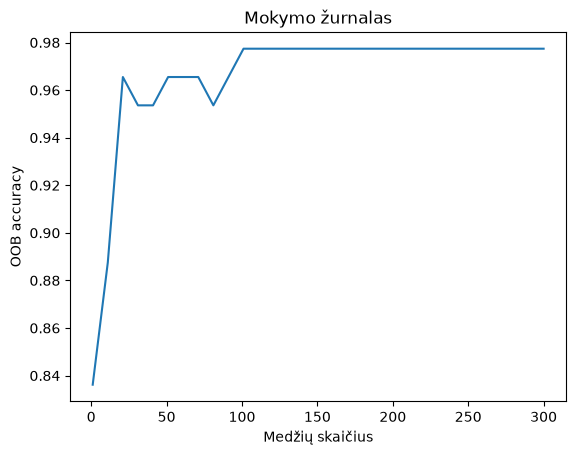

,požymis,TF-IDF n-grama,kiek kartų šaknyje
0,cpv_33696,,19.0
1,kw_positive_total,,13.0
2,kw_positive_groups,,12.0
3,tfidf_045,' rea',12.0
4,tfidf_046,' reag',11.0
5,tfidf_131,'ent',10.0
6,tfidf_333,'reag',10.0
7,cpv_336,,9.0
8,tfidf_106,'cin',8.0
9,tfidf_120,'eagen',8.0


In [8]:
inspector = forest.make_inspector()
logs = inspector.training_logs()
plt.plot([l.num_trees for l in logs], [l.evaluation.accuracy for l in logs])
plt.xlabel("Medžių skaičius"); plt.ylabel("OOB accuracy"); plt.title("Mokymo žurnalas"); plt.show()
importance = inspector.variable_importances()["NUM_AS_ROOT"]
ngram = {c: repr(n) for c, n in zip(text_matrix.columns, tfidf.get_feature_names_out())}  # tarpas = žodžio riba
top = pd.DataFrame([(v[0].name, ngram.get(v[0].name, ""), v[1]) for v in importance[:15]],
                   columns=["požymis", "TF-IDF n-grama", "kiek kartų šaknyje"])
top


## 9. Vieno medžio fragmentas

Miškas susideda iš 300 medžių; vienas medis rodomas tik iliustracijai.


In [9]:
tree_text = inspector.extract_tree(tree_idx=0)
print(str(tree_text)[:1500])


(tfidf_045 >= 0.06280459463596344; miss=False, score=0.11945411562919617)
    ├─(pos)─ (tfidf_183 >= 0.03642651438713074; miss=True, score=0.15858739614486694)
    │        ├─(pos)─ (tfidf_178 >= 0.06571879982948303; miss=False, score=0.21078094840049744)
    │        │        ├─(pos)─ ProbabilityValue([0.473239418971222, 0.526760581028778],n=5.175388336181641) (idx=8)
    │        │        └─(neg)─ ProbabilityValue([1.0, 0.0],n=17.144384384155273) (idx=7)
    │        └─(neg)─ (tfidf_033 >= 0.02462337724864483; miss=False, score=0.18168680369853973)
    │                 ├─(pos)─ ProbabilityValue([1.0, 0.0],n=9.796791076660156) (idx=6)
    │                 └─(neg)─ (tfidf_064 >= 0.11498308181762695; miss=False, score=0.21778060495853424)
    │                      ...
    └─(neg)─ (tfidf_307 >= 0.0926157534122467; miss=False, score=0.40064817667007446)
             ├─(pos)─ (tfidf_026 >= 0.1289437711238861; miss=False, score=0.47651922702789307)
             │        ├─(pos)─ Probabi

## 10. Slenksčio pasirinkimas validavimo aibėje (taip pat kaip NN)


In [10]:
val_score = forest.predict(val_tf, verbose=0).ravel()
candidates = np.round(np.arange(0.05, 0.96, 0.05), 2)
val_recall = [((val_score >= t) & (y["val"] == 1)).sum() / max(1, (y["val"] == 1).sum()) for t in candidates]
ok = [t for t, r in zip(candidates, val_recall) if r >= 0.9]
THRESHOLD = float(max(ok)) if ok else 0.5
print("Pasirinktas slenkstis:", THRESHOLD)


Pasirinktas slenkstis:

 0.2


## 11. Galutinis įvertinimas ir palyginimas su neuroniniu tinklu


In [11]:
test_score = forest.predict(test_tf, verbose=0).ravel()
rows = [majority_row, baseline_row,
        report("TF-DF miškas (slenkstis 0,5)", y["test"], (test_score >= 0.5).astype(int), test_score),
        report(f"TF-DF miškas (slenkstis {THRESHOLD})", y["test"], (test_score >= THRESHOLD).astype(int), test_score)]
df_pred = (test_score >= THRESHOLD).astype(int)
print(classification_report(y["test"], df_pred, target_names=["neaktualu", "aktualu"], zero_division=0))
print("Painiavos matrica (eilutės = tikra, stulpeliai = prognozė):\n", confusion_matrix(y["test"], df_pred))
results = pd.DataFrame(rows).round(3)
PRIVATE.joinpath("rezultatai").mkdir(exist_ok=True)
results.assign(test_fingerprint=SPLIT_FINGERPRINT).to_csv(PRIVATE / "rezultatai" / "1_3_tfdf.csv", index=False)
nn_file = PRIVATE / "rezultatai" / "1_3_nn.csv"
if nn_file.exists():
    nn_results = pd.read_csv(nn_file)
    assert (nn_results.test_fingerprint.astype(str) == SPLIT_FINGERPRINT).all(), "Testo aibės nesutampa!"
    results = pd.concat([results, nn_results[nn_results.modelis.str.startswith("Keras")].drop(columns="test_fingerprint")])
results.reset_index(drop=True)


              precision    recall  f1-score   support

   neaktualu       0.85      0.84      0.85        63
     aktualu       0.29      0.31      0.30        13

    accuracy                           0.75        76
   macro avg       0.57      0.57      0.57        76
weighted avg       0.76      0.75      0.75        76

Painiavos matrica (eilutės = tikra, stulpeliai = prognozė):
 [[53 10]
 [ 9  4]]


,modelis,accuracy,precision_1,recall_1,f1_1,praleista_aktualiu,klaidingai_aktualiu,PR_AUC
0,Visada 0 (dauguma),0.829,0.000,0.000,0.000,13,0,NaN
1,Bazinė raktinių žodžių taisyklė,0.789,0.444,0.923,0.600,1,15,NaN
2,"TF-DF miškas (slenkstis 0,5)",0.829,0.500,0.077,0.133,12,1,0.412
3,TF-DF miškas (slenkstis 0.2),0.750,0.286,0.308,0.296,9,10,0.412
4,"Keras NN (slenkstis 0,5)",0.803,0.333,0.154,0.211,11,4,0.467
5,Keras NN (slenkstis 0.2),0.829,0.500,0.615,0.552,5,8,0.467


## 12. Praleistos aktualios dalys


In [12]:
def show_errors(pred, title):
    test = raw[masks["test"]].assign(pred=pred)
    missed = test[(test.y == 1) & (test.pred == 0)]
    false_pos = test[(test.y == 0) & (test.pred == 1)]
    print(f"{title}: praleistos aktualios dalys ({len(missed)})")
    for _, r in missed.iterrows():
        print(" -", r.lot_title[:90], "|", r.source_url)
    print(f"\n{title}: klaidingai aktualiomis pažymėtos dalys ({len(false_pos)}, rodomos iki 8)")
    for _, r in false_pos.head(8).iterrows():
        print(" -", r.lot_title[:90])

show_errors(df_pred, 'TF-DF miškas')


TF-DF miškas: praleistos aktualios dalys (9)
 - Reagentai iš prekių katalogo: ABCAM. nuoroda į gamintojo internetinį puslapį: https://www. | https://ted.europa.eu/lt/notice/-/detail/323136-2026
 - Reagentai iš prekių katalogo: Biocare Medical. Nuoroda į gamintojo internetinį puslapį: ht | https://ted.europa.eu/lt/notice/-/detail/323136-2026
 - Reagentai iš prekių katalogo: CellMarque. Nuoroda į gamintojo internetinį puslapį: https:/ | https://ted.europa.eu/lt/notice/-/detail/323136-2026
 - Reagentai iš prekių katalogo: DCS. Nuoroda į gamintojo internetinį puslapį: https://www.dc | https://ted.europa.eu/lt/notice/-/detail/323136-2026
 - Reagentai iš prekių katalogo: Dianova. Nuoroda į gamintojo internetinį puslapį: https://ww | https://ted.europa.eu/lt/notice/-/detail/323136-2026
 - Reagentai iš prekių katalogo: SantaCruz. Nuoroda į gamintojo internetinį puslapį: https:// | https://ted.europa.eu/lt/notice/-/detail/323136-2026
 - 9 pirkimo dalis Jaučio serumo albuminas (BSA) | https://te

## 13. Išsaugoti, įkelti ir prognozuoti vieną pavyzdį


In [13]:
path = PRIVATE / "modeliai" / "1_3_pirkimo_dalies_tfdf"
path.parent.mkdir(exist_ok=True)
forest.save(path)
import tf_keras  # TF-DF modeliai yra Keras 2 (tf_keras) modeliai
reloaded = tf_keras.models.load_model(path)
same = np.allclose(reloaded.predict(test_tf, verbose=0).ravel(), test_score, atol=1e-5)
print("Įkeltas modelis duoda tas pačias prognozes:", same)
example = raw[masks["test"]].iloc[0]
print("Pavyzdys:", example.lot_title[:80], "→ tikimybė", round(float(test_score[0]), 3), "| žyma", example.y)


INFO:tensorflow:Assets written to: <projektas>/private/modeliai/1_3_pirkimo_dalies_tfdf/assets


INFO:tensorflow:Assets written to: <projektas>/private/modeliai/1_3_pirkimo_dalies_tfdf/assets


I0000 00:00:1794487388.284573 1282158 decision_forest.cc:808] Model loaded with 300 root(s), 5450 node(s), and 352 input feature(s).


Įkeltas modelis duoda tas pačias prognozes: True
Pavyzdys: 1. Rinkinių komplektas skirtas genų, susijusių su solidiniais navikais ir onkohe → tikimybė 0.323 | žyma 1


## 14. Išvados

Abu modeliai mokyti ir testuoti su ta pačia testo aibe. Interpretacija — pristatymo gide (`docs/1_3_1_5_pristatymo_gidas.md`).
